## Testing

In [1]:
import json

with open('dataset_25_04_2024.json', 'r', encoding = 'utf-8') as f:
    data = json.load(f)

In [2]:
data['0'].keys()

dict_keys(['text', 'entities', 'tokens', 'BIO_Tags'])

In [3]:
from collections import defaultdict
D = defaultdict(int)

for k,v in data.items():
    for x in data[k]['entities']:
        tag = x[-1]
        # print(tag)
        D[tag] += 1

In [4]:
D

defaultdict(int,
            {'WORK-OF-ART': 3206,
             'PER': 7851,
             'DATE': 2539,
             'LOC': 890,
             'ORG': 221})

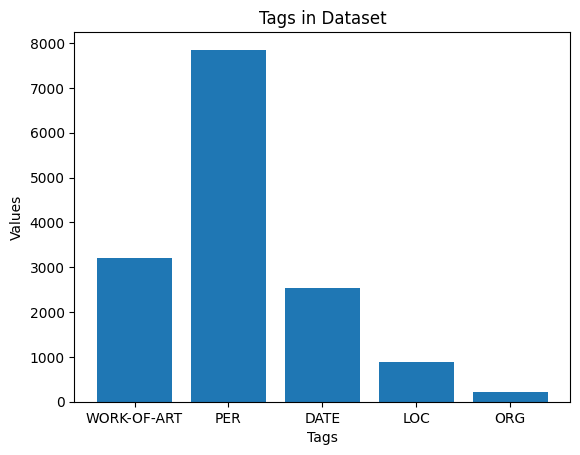

In [5]:
import matplotlib.pyplot as plt


# Extract keys and values from the dictionary
keys = list(D.keys())
values = list(D.values())

# Plotting
plt.bar(keys, values)
plt.xlabel('Tags')
plt.ylabel('Values')
plt.title('Tags in Dataset')
plt.show()


In [6]:
import pandas as pd

number_of_samples = len(data.keys())
number_of_tokens = 0
sents_lengths = 0
for k,v in data.items():
  sents_lengths += len(v['text'])
  number_of_tokens += len(v['tokens'])

List = [[number_of_samples], [sents_lengths], [number_of_tokens], [sents_lengths/number_of_samples], [number_of_tokens/number_of_samples]]
df = pd.DataFrame(list(map(list, zip(*List))), columns = ['Number of samples', 'Total length', 'Total tokens', 'Average length by sample', 'Average tokens by sample'])
df

,Number of samples,Total length,Total tokens,Average length by sample,Average tokens by sample
0,1567,1064459,201613,679.297384,128.661774


In [7]:
from spacy import displacy

def display_tags(sentence,entities):
  colors = {'PER':'#00ffbb', 'DATE':'#ffbb00', 'LOC':'#ff00ff', 'WORK-OF-ART':'#cedf0e'}
  options = {'colors':colors}

  XX = []
  for ent in entities:
    XX.append({"start":ent[0], "end":ent[1], "label":ent[2]})

  ex = [{"text": sentence,
       "ents": XX,
       "title": None}]
  return displacy.render(ex, style="ent", manual=True, options=options)



In [8]:
ex = [{"text": "But Google is starting from behind.",
       "ents": [{"start": 4, "end": 10, "label": "ORG"}],
       "title": None}]


In [9]:
entities = data['2']['entities']
text = data['2']['text']

In [10]:
display_tags(text,entities)

In [11]:
from collections import defaultdict
D = defaultdict(int)

for k,v in data.items():
    for x in data[k]['entities']:
        tag = x[-1]
        # print(tag)
        D[tag] += 1

In [12]:
D

defaultdict(int,
            {'WORK-OF-ART': 3206,
             'PER': 7851,
             'DATE': 2539,
             'LOC': 890,
             'ORG': 221})

In [13]:
from collections import defaultdict
T = defaultdict(int)

for k,v in data.items():
    for x in data[k]['BIO_Tags']:
      if x != 'O':
        tag = x[2:]
        T[tag] += 1

    # print(k)
    # print(data[k])
    # print(T)
    # break


In [14]:
T

defaultdict(int,
            {'WORK-OF-ART': 16184,
             'PER': 11653,
             'DATE': 6196,
             'LOC': 1007,
             'ORG': 443})

In [15]:
for k,v in D.items():
  print(k, T[k]/D[k])

WORK-OF-ART 5.048034934497816
PER 1.484269519806394
DATE 2.4403308389129577
LOC 1.1314606741573034
ORG 2.004524886877828
